# Gradient descent and quadratic cost

A controlled analysis of iteration budget and learning rate for a two-parameter linear regression model.

## Data and objective

The five observations are x = [1, 2, 3, 4, 5] and y = [5, 7, 9, 11, 13]. They lie exactly on y = 2x + 3. The model is ŷ = mx + b and the cost is mean squared error: J(m,b) = mean((y − ŷ)²), without a factor of ½. The unique optimum is m = 2, b = 3, J = 0.

Each experiment starts from m = b = 0 and updates both parameters using gradients evaluated at the same pre-update state. All five observations contribute to every update; this is deterministic full-batch gradient descent.

## Conceptual context

Mayo (2017) explains the role of gradients in parameter updates and distinguishes batch, stochastic and mini-batch training. This analysis uses full-batch gradients calculated directly for a linear model. Backpropagation computes derivatives through a network; gradient descent uses derivatives to update parameters. No multilayer backpropagation is needed here.

The article provides a conceptual introduction rather than convergence guarantees. A positive derivative specifies a direction of increasing cost; it does not by itself establish that a previous step overshot the optimum. The update moves against the gradient. The local-minimum discussion is also distinct from this strictly convex problem, whose unique minimum is known. The stability bound and controlled runs provide the relevant evidence for step-size selection here.

Mayo, M. (2017) ‘Neural network foundations, explained: updating weights with gradient descent & backpropagation’, *KDnuggets*, 25 October. Available at: [https://www.kdnuggets.com/2017/10/neural-network-foundations-explained-gradient-descent.html](https://www.kdnuggets.com/2017/10/neural-network-foundations-explained-gradient-descent.html) (Accessed: 14 October 2026).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('NumPy:',np.__version__)
x=np.array([1,2,3,4,5],dtype=float)
y=np.array([5,7,9,11,13],dtype=float)
A=np.column_stack([x,np.ones_like(x)])

def cost(theta):
    return float(np.mean((y-A@theta)**2))

def gradient(theta):
    return -(2/len(x))*A.T@(y-A@theta)

def run_descent(learning_rate=0.08,iterations=100):
    theta=np.zeros(2)
    rows=[{'Updates':0,'Slope':theta[0],'Intercept':theta[1],'MSE':cost(theta),'Gradient norm':float(np.linalg.norm(gradient(theta)))}]
    for step in range(1,iterations+1):
        theta=theta-learning_rate*gradient(theta)
        rows.append({'Updates':step,'Slope':theta[0],'Intercept':theta[1],'MSE':cost(theta),'Gradient norm':float(np.linalg.norm(gradient(theta)))})
    return pd.DataFrame(rows)

baseline=run_descent()
display(baseline.loc[[0,1,10,50,99,100]].round(8))
assert cost(np.array([2.,3.]))==0
assert np.allclose(np.linalg.lstsq(A,y,rcond=None)[0],[2,3])


Updates,Slope,Intercept,MSE,Gradient norm
0,0.000000,0.000000,89.000000,64.560050
1,4.960000,1.440000,71.105600,57.649867
10,1.630886,1.038341,9.691269,20.816006
50,2.150586,2.420784,0.061598,0.302260
99,2.041711,2.849549,0.004121,0.052793
100,2.040516,2.853600,0.003901,0.051364


NumPy: 2.4.4


## Baseline reporting check

The reference programme prints the cost calculated before an update alongside the slope and intercept after that update. Its iteration index begins at zero. The final printed line therefore pairs parameters after 100 updates with cost after 99 updates. The tables in this analysis use completed-update counts and evaluate cost at the same parameters shown in each row. This changes reporting, not the update rule.

In [2]:
report=pd.DataFrame([
    {'Reference line':0,'Post-update slope':baseline.iloc[1].Slope,'Post-update intercept':baseline.iloc[1].Intercept,'Printed pre-update cost':baseline.iloc[0].MSE,'Aligned post-update cost':baseline.iloc[1].MSE},
    {'Reference line':99,'Post-update slope':baseline.iloc[100].Slope,'Post-update intercept':baseline.iloc[100].Intercept,'Printed pre-update cost':baseline.iloc[99].MSE,'Aligned post-update cost':baseline.iloc[100].MSE}
])
display(report.round(8))


Reference line,Post-update slope,Post-update intercept,Printed pre-update cost,Aligned post-update cost
0,4.960000,1.4400,89.000000,71.105600
99,2.040516,2.8536,0.004121,0.003901


## Iteration budget

The learning rate remains 0.08. Runs with different budgets use identical data, initial parameters and update rules. Costs are measured after the stated number of completed updates.

Updates,Slope,Intercept,MSE,Gradient norm
1.0,4.960000,1.440000,7.110560e+01,5.764987e+01
10.0,1.630886,1.038341,9.691269e+00,2.081601e+01
50.0,2.150586,2.420784,6.159788e-02,3.022603e-01
100.0,2.040516,2.853600,3.900707e-03,5.136370e-02
500.0,2.000001,2.999997,1.159798e-12,8.855769e-07
1000.0,2.000000,3.000000,1.432017e-24,9.840443e-13


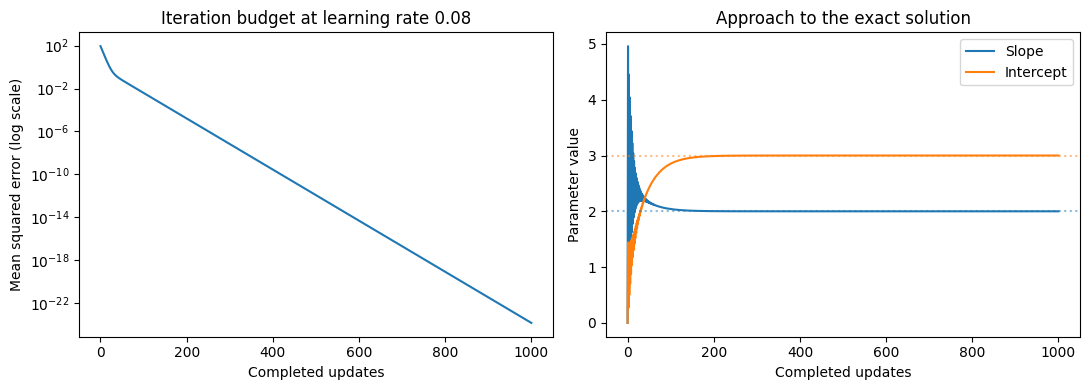

In [3]:
budgets=[1,10,50,100,500,1000]
iteration_results=pd.DataFrame([run_descent(iterations=n).iloc[-1] for n in budgets]).reset_index(drop=True)
display(iteration_results)
long_run=run_descent(iterations=1000)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].semilogy(long_run.Updates,long_run.MSE)
axes[0].set(xlabel='Completed updates',ylabel='Mean squared error (log scale)',title='Iteration budget at learning rate 0.08')
axes[1].plot(long_run.Updates,long_run.Slope,label='Slope')
axes[1].plot(long_run.Updates,long_run.Intercept,label='Intercept')
axes[1].axhline(2,color='tab:blue',linestyle=':',alpha=0.5)
axes[1].axhline(3,color='tab:orange',linestyle=':',alpha=0.5)
axes[1].set(xlabel='Completed updates',ylabel='Parameter value',title='Approach to the exact solution')
axes[1].legend();plt.tight_layout();plt.show()


## Learning-rate comparison

Each rate is evaluated for 100 updates. Stable and unstable runs are plotted separately to avoid a diverging curve obscuring the smaller costs. Increasing the iteration budget cannot correct an unstable fixed learning rate.

Learning rate,Updates,Slope,Intercept,MSE,Gradient norm
0.001,100.0,2.368512e+00,7.373704e-01,1.610466e+00,5.938017e+00
0.010,100.0,2.448468e+00,1.380887e+00,4.771639e-01,5.680269e-01
0.050,100.0,2.114386e+00,2.587032e+00,3.104173e-02,1.448799e-01
0.080,100.0,2.040516e+00,2.853600e+00,3.900707e-03,5.136370e-02
0.084,100.0,1.280305e+00,2.663502e+00,7.263861e+00,1.853688e+01
0.085,100.0,-6.023248e+00,6.452260e-01,8.270002e+02,1.978299e+02
0.100,100.0,-9.353021e+13,-2.590637e+13,1.114362e+29,2.296429e+15


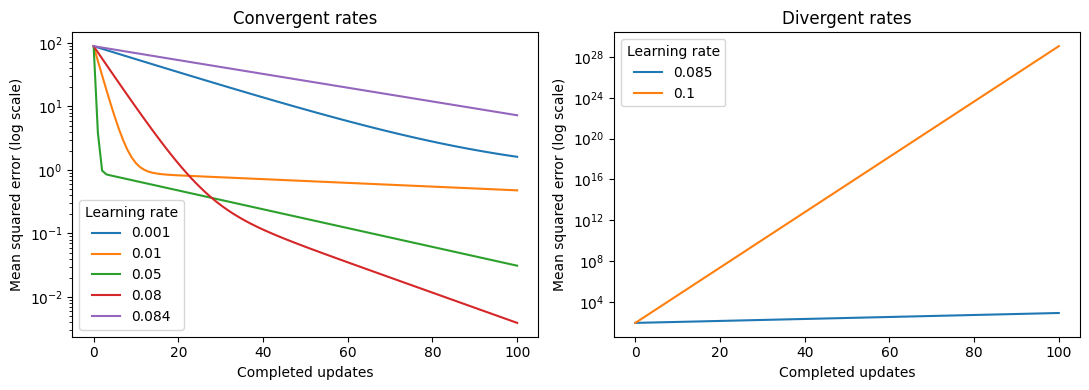

In [4]:
rates=[0.001,0.01,0.05,0.08,0.084,0.085,0.1]
rate_runs={rate:run_descent(rate,100) for rate in rates}
rate_results=pd.DataFrame([dict({'Learning rate':rate},**history.iloc[-1].to_dict()) for rate,history in rate_runs.items()])
display(rate_results)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for rate,history in rate_runs.items():
    ax=axes[0] if rate<=0.084 else axes[1]
    ax.semilogy(history.Updates,history.MSE,label=str(rate))
for ax,label in zip(axes,['Convergent rates','Divergent rates']):
    ax.set(xlabel='Completed updates',ylabel='Mean squared error (log scale)',title=label)
    ax.legend(title='Learning rate')
plt.tight_layout();plt.show()


## Stability and numerical verification

For this quadratic objective, the Hessian is H = (2/n)AᵀA = [[22, 6], [6, 2]]. The parameter error follows eₖ₊₁ = (I − αH)eₖ. Convergence from any initial parameters requires 0 < α < 2/λmax(H). This bound depends on the feature scale and the precise normalisation of the cost. It is not a universal learning-rate recommendation.

In [5]:
H=(2/len(x))*A.T@A
eigenvalues=np.linalg.eigvalsh(H)
upper_bound=float(2/eigenvalues[-1])
display(pd.DataFrame({'Hessian eigenvalue':eigenvalues}))
print('Stable upper bound (strict):',upper_bound)
test_point=np.array([0.7,-0.4]);epsilon=1e-6
numeric=np.array([(cost(test_point+epsilon*np.eye(2)[j])-cost(test_point-epsilon*np.eye(2)[j]))/(2*epsilon) for j in range(2)])
assert np.allclose(numeric,gradient(test_point),rtol=1e-7,atol=1e-7)
assert np.all(np.diff(baseline.MSE)<=1e-12)
assert all(np.isfinite(h.MSE).all() for h in rate_runs.values())
assert np.allclose(long_run.iloc[-1][['Slope','Intercept']].to_numpy(dtype=float),[2,3],atol=1e-10)
print('Checks passed: finite-difference gradient, exact least-squares solution, aligned cost and baseline cost decrease.')
summary={'baseline':baseline.iloc[-1].to_dict(),'initial_cost':baseline.iloc[0].MSE,'first_update':baseline.iloc[1].to_dict(),'reference_last_cost':baseline.iloc[99].MSE,'iterations':iteration_results.to_dict('records'),'rates':rate_results.to_dict('records'),'eigenvalues':eigenvalues.tolist(),'stable_upper_bound':upper_bound}


Hessian eigenvalue
0.338096
23.661904


Stable upper bound (strict): 0.08452405257734978
Checks passed: finite-difference gradient, exact least-squares solution, aligned cost and baseline cost decrease.


## Interpretation and limitations

Small rates move slowly, whereas rates close to the stability boundary can alternate across the optimum with weak damping. Above the boundary, that oscillation grows and cost diverges. Additional iterations improve this noiseless training fit only when the update is stable. Near the exact solution, floating-point precision limits further measurable progress.

No local minima compete with the global minimum here: the objective is a strictly convex quadratic. Cost reduction measures optimisation on these five points, not predictive performance on unseen data. Scaling, noise, regularisation and stochastic updates would change the practical optimisation problem. A cost or gradient tolerance combined with an iteration limit would be a stronger stopping policy than a budget alone.

## Provenance and reproducibility

Adapted from `Unit08 Ex4 gradient_descent_cost_function.ipynb`, which credits codebasics. The dataset, zero initialisation, gradient formulas and reference settings are retained. The analysis adds aligned cost reporting, controlled comparisons and numerical checks. Cells were executed sequentially in an independent Python namespace, with outputs embedded. Analysis and editorial preparation used AI assistance.